# Network Protocol Classification Using Machine Learning

## Step 1: Dataset Repair and Preparation

The original merged dataset contained 14 columns because two groups of the same seven packet columns were merged incorrectly.

I repaired the structure and created one correct dataset with these columns:

- No.
- Time
- Source
- Destination
- Protocol
- Length
- Info

All valid packet records were preserved. No machine learning model is trained in this step.

In [ ]:
import csv
from collections import Counter
from pathlib import Path
import pandas as pd

input_path = Path("/content/KT_GameBox_Merged.csv")
output_path = Path("/content/KT_GameBox_Corrected.csv")
rejected_path = Path("/content/KT_GameBox_Malformed_Rows.csv")

columns = ["No.", "Time", "Source", "Destination", "Protocol", "Length", "Info"]

def has_data(values):
    return any(value.strip() for value in values)

def is_header(values):
    return [value.strip().strip('"') for value in values] == columns

def remove_extra_quotes(value):
    value = value.strip()
    if len(value) >= 2 and value.startswith('"') and value.endswith('"'):
        return value[1:-1]
    return value

stats = Counter()
missing = Counter()

with input_path.open("r", encoding="utf-8-sig", newline="") as source, \
     output_path.open("w", encoding="utf-8", newline="") as cleaned_file, \
     rejected_path.open("w", encoding="utf-8", newline="") as rejected_file:

    reader = csv.reader(source)
    writer = csv.writer(cleaned_file)
    rejected_writer = csv.writer(rejected_file)

    original_header = next(reader)
    print("Original column count:", len(original_header))
    print("Original headers:", original_header)

    writer.writerow(columns)
    rejected_writer.writerow(["Original line number", "Original row"])

    for line_number, row in enumerate(reader, start=2):
        stats["input_rows"] += 1

        if len(row) != 14:
            stats["malformed_rows"] += 1
            rejected_writer.writerow([line_number, row])
            continue

        left_group = row[:7]
        right_group = row[7:]

        if is_header(left_group) or is_header(right_group):
            stats["repeated_header_rows"] += 1
            continue

        if not has_data(left_group) and not has_data(right_group):
            stats["blank_rows"] += 1
            continue

        records = []

        if has_data(left_group):
            stats["left_group_records"] += 1
            records.append(left_group)

        if has_data(right_group):
            stats["right_group_records"] += 1
            records.append([remove_extra_quotes(value) for value in right_group])

        if has_data(left_group) and has_data(right_group):
            stats["both_groups_populated"] += 1

        for record in records:
            writer.writerow(record)
            stats["output_rows"] += 1

            for column, value in zip(columns, record):
                if not value.strip():
                    missing[column] += 1

print("\nRepair results")
print("Input rows:", stats["input_rows"])
print("Output packet rows:", stats["output_rows"])
print("Left-group records:", stats["left_group_records"])
print("Right-group records:", stats["right_group_records"])
print("Repeated headers:", stats["repeated_header_rows"])
print("Malformed rows saved separately:", stats["malformed_rows"])
print("Missing values:", dict(missing))

# Inspect the repaired file
df = pd.read_csv(output_path, low_memory=False)

print("\nShape (rows, columns):", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate complete rows:", df.duplicated().sum())

print("\nProtocol counts:")
print(df["Protocol"].value_counts(dropna=False))

print("\nInvalid numeric Length values:")
print(pd.to_numeric(df["Length"], errors="coerce").isna().sum())

print("\nInvalid Time values:")
print(pd.to_datetime(df["Time"], errors="coerce").isna().sum())

Original column count: 14
Original headers: ['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info', '"No."', '"Time"', '"Source"', '"Destination"', '"Protocol"', '"Length"', '"Info"']

Repair results
Input rows: 114338
Output packet rows: 114337
Left-group records: 114337
Right-group records: 0
Repeated headers: 0
Malformed rows saved separately: 1
Missing values: {}

Shape (rows, columns): (114337, 7)

Data types:
No.            float64
Time            object
Source          object
Destination     object
Protocol        object
Length         float64
Info            object
dtype: object

Missing values:
No.            0
Time           0
Source         0
Destination    0
Protocol       0
Length         0
Info           0
dtype: int64

Duplicate complete rows: 0

Protocol counts:
Protocol
UDP        101230
TCP         12961
TLSv1          81
TLSv1.3        42
TLSv1.2        12
DNS            10
FMTP            1
Name: count, dtype: int64

Invalid numeric Length values:
0



## Step 2: Dataset Inspection

In this step, I load the corrected dataset and inspect:

- Number of rows and columns
- Column names
- First and last packet records
- Data types
- Missing values
- Duplicate rows
- Number of packets in each protocol

This helps me understand the data before cleaning it.

In [ ]:
import pandas as pd

file_path = "/content/KT_GameBox_Corrected.csv"

df = pd.read_csv(file_path, low_memory=False)

print("Dataset shape (rows, columns):", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 packet records:")
display(df.head())

print("\nLast 5 packet records:")
display(df.tail())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nProtocol counts:")
print(df["Protocol"].value_counts(dropna=False))

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape (rows, columns): (114337, 7)

Column names:
['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info']

First 5 packet records:


,No.,Time,Source,Destination,Protocol,Length,Info
0,1.0,2022-10-07 11:13:55.821154,192.0.0.2,10.215.173.2,TCP,60.0,53524 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...
1,2.0,2022-10-07 11:13:56.062609,10.215.173.1,10.215.173.2,DNS,68.0,Standard query 0x1116 A gbc.play.ktgamebox.com
2,3.0,2022-10-07 11:13:56.093017,10.215.173.2,10.215.173.1,DNS,168.0,Standard query response 0x1116 A gbc.play.ktga...
3,4.0,2022-10-07 11:13:56.096288,10.215.173.1,211.252.120.14,TCP,60.0,38050 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...
4,5.0,2022-10-07 11:13:56.117668,211.252.120.14,10.215.173.1,TCP,48.0,"443 > 38050 [SYN, ACK] Seq=0 Ack=1 Win=2048 ..."



Last 5 packet records:


,No.,Time,Source,Destination,Protocol,Length,Info
114332,114333.0,2022-10-07 11:16:04.801255,183.110.235.46,10.215.173.1,UDP,1300.0,42632 > 44855 Len=1272
114333,114334.0,2022-10-07 11:16:04.801448,183.110.235.46,10.215.173.1,UDP,1300.0,42632 > 44855 Len=1272
114334,114335.0,2022-10-07 11:16:04.801641,183.110.235.46,10.215.173.1,UDP,1300.0,42632 > 44855 Len=1272
114335,114336.0,2022-10-07 11:16:04.801836,183.110.235.46,10.215.173.1,UDP,1300.0,42632 > 44855 Len=1272
114336,114337.0,2022-10-07 11:16:04.802031,183.110.235.46,10.215.173.1,UDP,1210.0,42632 > 44855 Len=1182



Data types:
No.            float64
Time            object
Source          object
Destination     object
Protocol        object
Length         float64
Info            object
dtype: object

Missing values:
No.            0
Time           0
Source         0
Destination    0
Protocol       0
Length         0
Info           0
dtype: int64

Protocol counts:
Protocol
UDP        101230
TCP         12961
TLSv1          81
TLSv1.3        42
TLSv1.2        12
DNS            10
FMTP            1
Name: count, dtype: int64

Duplicate rows: 0


## Step 3: Data Cleaning

For machine learning, important values must be valid.

I convert:

- `No.` into a numeric value
- `Time` into date and time format
- `Length` into a numeric value

I remove only the few rows where `No.`, `Time`, `Protocol`, or `Length` is missing or invalid. These columns are important for the planned analysis and prediction.

The cleaned dataset is saved as `KT_GameBox_Cleaned.csv`.

In [ ]:
# Make a separate copy for cleaning
df_clean = df.copy()

# Convert important columns to the correct data type
df_clean["No."] = pd.to_numeric(df_clean["No."], errors="coerce")
df_clean["Time"] = pd.to_datetime(df_clean["Time"], errors="coerce")
df_clean["Length"] = pd.to_numeric(df_clean["Length"], errors="coerce")

# Remove only unusable rows for our project
df_clean = df_clean.dropna(subset=["No.", "Time", "Protocol", "Length"])

# Make packet number a whole number
df_clean["No."] = df_clean["No."].astype(int)

# Reset row numbering after removal
df_clean = df_clean.reset_index(drop=True)

# Save a new clean file; the corrected file remains unchanged
clean_file_path = "/content/KT_GameBox_Cleaned.csv"
df_clean.to_csv(clean_file_path, index=False)

print("Original repaired dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))

print("\nClean data types:")
print(df_clean.dtypes)

print("\nMissing values after cleaning:")
print(df_clean[["No.", "Time", "Protocol", "Length"]].isnull().sum())

display(df_clean.head())

Original repaired dataset shape: (114337, 7)
Clean dataset shape: (114337, 7)
Rows removed: 0

Clean data types:
No.                     int64
Time           datetime64[ns]
Source                 object
Destination            object
Protocol               object
Length                float64
Info                   object
dtype: object

Missing values after cleaning:
No.         0
Time        0
Protocol    0
Length      0
dtype: int64


,No.,Time,Source,Destination,Protocol,Length,Info
0,1,2022-10-07 11:13:55.821154,192.0.0.2,10.215.173.2,TCP,60.0,53524 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...
1,2,2022-10-07 11:13:56.062609,10.215.173.1,10.215.173.2,DNS,68.0,Standard query 0x1116 A gbc.play.ktgamebox.com
2,3,2022-10-07 11:13:56.093017,10.215.173.2,10.215.173.1,DNS,168.0,Standard query response 0x1116 A gbc.play.ktga...
3,4,2022-10-07 11:13:56.096288,10.215.173.1,211.252.120.14,TCP,60.0,38050 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...
4,5,2022-10-07 11:13:56.117668,211.252.120.14,10.215.173.1,TCP,48.0,"443 > 38050 [SYN, ACK] Seq=0 Ack=1 Win=2048 ..."


## Step 4: Exploratory Data Analysis

In this step, I study the distribution of network protocols and packet lengths.

This helps me understand which protocols appear most often and whether the dataset is balanced or imbalanced.

Protocol distribution:


,Packet Count,Percentage
Protocol,,
UDP,101230,88.54
TCP,12961,11.34
TLSv1,81,0.07
TLSv1.3,42,0.04
TLSv1.2,12,0.01
DNS,10,0.01
FMTP,1,0.00


/tmp/ipykernel_2181/3198987896.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


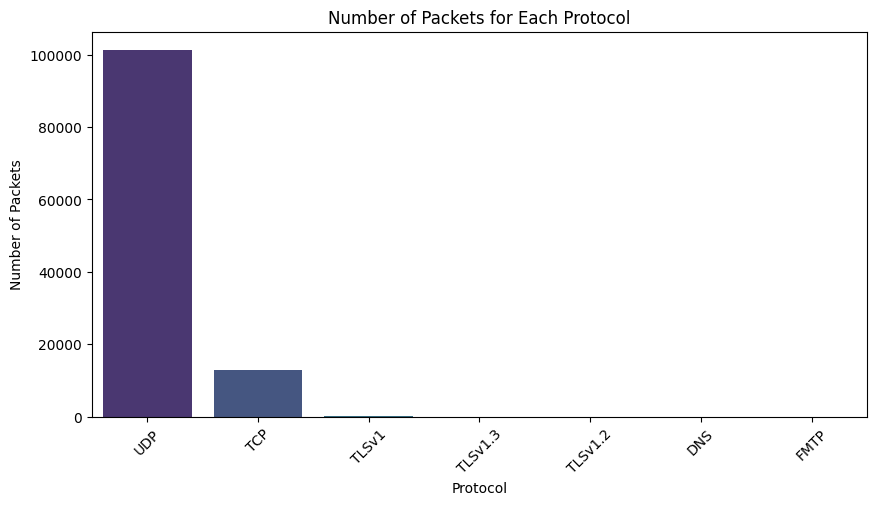


Packet Length Statistics:


,Length
count,114337.000000
mean,1267.688710
std,896.108225
min,32.000000
25%,1300.000000
50%,1300.000000
75%,1300.000000
max,10000.000000


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count packets for each protocol
protocol_counts = df_clean["Protocol"].value_counts()

# Show count and percentage for each protocol
protocol_summary = pd.DataFrame({
    "Packet Count": protocol_counts,
    "Percentage": (protocol_counts / len(df_clean) * 100).round(2)
})

print("Protocol distribution:")
display(protocol_summary)

# Create protocol count chart
plt.figure(figsize=(10, 5))
sns.barplot(
    x=protocol_counts.index,
    y=protocol_counts.values,
    palette="viridis"
)

plt.title("Number of Packets for Each Protocol")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")
plt.xticks(rotation=45)
plt.show()

# Show packet length statistics
print("\nPacket Length Statistics:")
display(df_clean["Length"].describe())

## Step 5: Packet Length Distribution

This chart shows how often different packet sizes occur in the network traffic.

Packet length is an important feature because different protocols may use packets of different sizes.

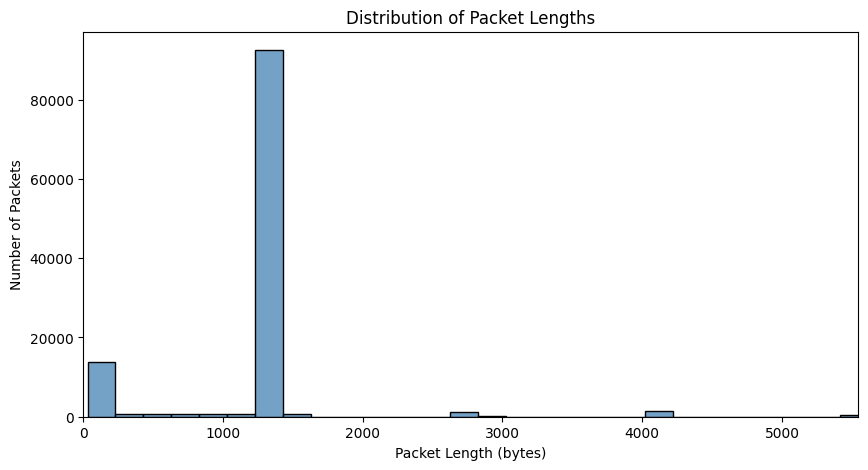

The graph displays packet lengths up to: 5545.0 bytes
This includes 99% of the packet records.


In [ ]:
# Find the packet length that includes 99% of the data
length_limit = df_clean["Length"].quantile(0.99)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="Length",
    bins=50,
    color="steelblue"
)

# Focus the graph on 99% of packet lengths so extreme values do not hide the pattern
plt.xlim(0, length_limit)

plt.title("Distribution of Packet Lengths")
plt.xlabel("Packet Length (bytes)")
plt.ylabel("Number of Packets")
plt.show()

print("The graph displays packet lengths up to:", round(length_limit, 2), "bytes")
print("This includes 99% of the packet records.")

## Step 6: Feature Engineering

The `Time` column contains a full date and time value.

For this project, I extract Hour, Minute, and Second from the Time column. These new columns may help the machine learning model identify patterns in network traffic at different times.

In [ ]:
# Create a copy with new features
df_features = df_clean.copy()

# Extract time-based features
df_features["Hour"] = df_features["Time"].dt.hour
df_features["Minute"] = df_features["Time"].dt.minute
df_features["Second"] = df_features["Time"].dt.second

# Show the original time and the new extracted features
display(df_features[["Time", "Hour", "Minute", "Second", "Length", "Protocol"]].head())

print("New dataset shape:", df_features.shape)

# Save the dataset with engineered features
feature_file_path = "/content/KT_GameBox_Featured.csv"
df_features.to_csv(feature_file_path, index=False)

print("Feature-engineered dataset saved as:", feature_file_path)

,Time,Hour,Minute,Second,Length,Protocol
0,2022-10-07 11:13:55.821154,11,13,55,60.0,TCP
1,2022-10-07 11:13:56.062609,11,13,56,68.0,DNS
2,2022-10-07 11:13:56.093017,11,13,56,168.0,DNS
3,2022-10-07 11:13:56.096288,11,13,56,60.0,TCP
4,2022-10-07 11:13:56.117668,11,13,56,48.0,TCP


New dataset shape: (114337, 10)
Feature-engineered dataset saved as: /content/KT_GameBox_Featured.csv


## Step 7: Feature Selection and Target Variable

The input columns used by the machine learning model are called features.

For this project, I use:

- Length
- Hour
- Minute
- Second

The output column is called the target variable. The target variable is Protocol because the model will learn to predict the network protocol.

In [ ]:
# Select input features for the machine learning model
feature_columns = ["Length", "Hour", "Minute", "Second"]

X = df_features[feature_columns]

# Select the target variable
y = df_features["Protocol"]

print("Selected feature columns:")
print(feature_columns)

print("\nFeature data shape:", X.shape)
print("Target data shape:", y.shape)

print("\nFirst 5 feature rows:")
display(X.head())

print("\nFirst 5 target values:")
display(y.head())

print("\nNumber of different protocols:", y.nunique())
print("\nProtocols included in the target:")
print(sorted(y.unique()))

Selected feature columns:
['Length', 'Hour', 'Minute', 'Second']

Feature data shape: (114337, 4)
Target data shape: (114337,)

First 5 feature rows:


,Length,Hour,Minute,Second
0,60.0,11,13,55
1,68.0,11,13,56
2,168.0,11,13,56
3,60.0,11,13,56
4,48.0,11,13,56



First 5 target values:


,Protocol
0,TCP
1,DNS
2,DNS
3,TCP
4,TCP



Number of different protocols: 7

Protocols included in the target:
['DNS', 'FMTP', 'TCP', 'TLSv1', 'TLSv1.2', 'TLSv1.3', 'UDP']


## Step 8: Encoding the Target Variable

Machine learning models require numeric values.

The Protocol column contains text values such as UDP, TCP, and DNS. I convert each protocol name into a numeric label.

For example, the model may use a number such as 0 for DNS or 7 for UDP. These numbers are labels only; they do not show that one protocol is greater than another.

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create the encoder
label_encoder = LabelEncoder()

# Convert protocol names into numeric labels
y_encoded = label_encoder.fit_transform(y)

# Create a table showing the protocol-to-number mapping
protocol_mapping = pd.DataFrame({
    "Protocol": label_encoder.classes_,
    "Encoded Value": range(len(label_encoder.classes_))
})

print("Protocol encoding mapping:")
display(protocol_mapping)

print("\nFirst 10 original protocol values:")
print(y.head(10).tolist())

print("\nFirst 10 encoded protocol values:")
print(y_encoded[:10])

Protocol encoding mapping:


,Protocol,Encoded Value
0,DNS,0
1,FMTP,1
2,TCP,2
3,TLSv1,3
4,TLSv1.2,4
5,TLSv1.3,5
6,UDP,6



First 10 original protocol values:
['TCP', 'DNS', 'DNS', 'TCP', 'TCP', 'TCP', 'TLSv1.3', 'TCP', 'DNS', 'TLSv1.3']

First 10 encoded protocol values:
[2 0 0 2 2 2 5 2 0 5]


## Step 9: Sampling and Train-Test Split

The complete dataset has more than 760,000 packet records. To train models efficiently, I create an approximately 100,000-row sample while keeping records from every protocol.

I split the data into:

- Training data (80%): used to teach the model
- Testing data (20%): used to check the model on unseen packets

In [ ]:
from sklearn.model_selection import train_test_split

sample_size = 100_000
sample_fraction = sample_size / len(df_features)

sampled_groups = []

for protocol, group in df_features.groupby("Protocol"):
    rows_to_keep = max(2, round(len(group) * sample_fraction))
    rows_to_keep = min(rows_to_keep, len(group))

    sampled_groups.append(
        group.sample(n=rows_to_keep, random_state=42)
    )

model_df = pd.concat(sampled_groups, ignore_index=True)
model_df = model_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Check protocol counts in the sample
protocol_counts_sample = model_df["Protocol"].value_counts()

print("Protocol counts before split:")
print(protocol_counts_sample)

# A protocol needs at least 2 examples for a stratified split
valid_protocols = protocol_counts_sample[protocol_counts_sample >= 2].index

excluded_protocols = protocol_counts_sample[protocol_counts_sample < 2]

print("\nProtocols excluded only from model training:")
print(excluded_protocols)

# Keep only protocols that have at least 2 records
model_df = model_df[model_df["Protocol"].isin(valid_protocols)].copy()

# Select features and encoded target
X_model = model_df[["Length", "Hour", "Minute", "Second"]]
y_model = label_encoder.transform(model_df["Protocol"])

# Create 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.20,
    random_state=42,
    stratify=y_model
)

print("\nFinal working sample shape:", model_df.shape)
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Protocol counts before split:
Protocol
UDP        88537
TCP        11336
TLSv1         71
TLSv1.3       37
TLSv1.2       10
DNS            9
FMTP           1
Name: count, dtype: int64

Protocols excluded only from model training:
Protocol
FMTP    1
Name: count, dtype: int64

Final working sample shape: (100000, 10)
Training feature shape: (80000, 4)
Testing feature shape: (20000, 4)


## Step 10: Feature Scaling

The features use different ranges. For example, Hour ranges from 0 to 23, while Length can be much larger.

Feature scaling puts the input values on a similar scale. This is especially important for Logistic Regression and K-Nearest Neighbors.

The scaler is fitted only on training data to prevent data leakage.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Learn scaling values from training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to testing data
X_test_scaled = scaler.transform(X_test)

print("First 5 rows before scaling:")
display(X_train.head())

print("\nFirst 5 rows after scaling:")
display(pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
).head())

print("\nScaling completed successfully.")

First 5 rows before scaling:


,Length,Hour,Minute,Second
63740,1300.0,11,15,19
10846,1300.0,11,15,22
52478,4149.0,11,14,20
92232,1300.0,11,15,40
46167,52.0,11,14,31



First 5 rows after scaling:


,Length,Hour,Minute,Second
0,0.038275,0.0,0.757556,-0.567294
1,0.038275,0.0,0.757556,-0.396266
2,3.229702,0.0,-0.996757,-0.510285
3,0.038275,0.0,0.757556,0.629907
4,-1.359724,0.0,-0.996757,0.116820



Scaling completed successfully.


## Step 11: Logistic Regression Model

Logistic Regression is a classification algorithm. It learns the relationship between the input features and the protocol labels.

I train the model using the training data and evaluate it using the unseen testing data.

In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create and train the Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

# Predict protocols for unseen testing data
y_pred_logistic = logistic_model.predict(X_test_scaled)

# Calculate accuracy
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

# Keep the result for final model comparison
model_results = {
    "Logistic Regression": logistic_accuracy
}

# Use only labels included in this model experiment
model_labels = np.unique(y_model)
model_target_names = label_encoder.inverse_transform(model_labels)

print("Logistic Regression Accuracy:", round(logistic_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_logistic,
    labels=model_labels,
    target_names=model_target_names,
    zero_division=0
))

Logistic Regression Accuracy: 89.83 %

Classification Report:
              precision    recall  f1-score   support

         DNS       0.00      0.00      0.00         2
         TCP       0.99      0.11      0.20      2267
       TLSv1       0.00      0.00      0.00        14
     TLSv1.2       0.00      0.00      0.00         2
     TLSv1.3       0.00      0.00      0.00         8
         UDP       0.90      1.00      0.95     17707

    accuracy                           0.90     20000
   macro avg       0.31      0.19      0.19     20000
weighted avg       0.91      0.90      0.86     20000



## Step 12: K-Nearest Neighbors Model

KNN predicts a packet’s protocol by finding the most similar packets in the training data.

I use 5 nearest neighbors. Feature scaling is important for KNN, so I use the scaled training and testing data.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Create and train the KNN model
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

knn_model.fit(X_train_scaled, y_train)

# Predict protocols for testing data
y_pred_knn = knn_model.predict(X_test_scaled)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, y_pred_knn)

# Save result for later comparison
model_results["KNN"] = knn_accuracy

print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    labels=model_labels,
    target_names=model_target_names,
    zero_division=0
))

KNN Accuracy: 99.54 %

Classification Report:
              precision    recall  f1-score   support

         DNS       0.00      0.00      0.00         2
         TCP       0.99      0.98      0.98      2267
       TLSv1       0.36      0.29      0.32        14
     TLSv1.2       0.00      0.00      0.00         2
     TLSv1.3       0.67      0.50      0.57         8
         UDP       1.00      1.00      1.00     17707

    accuracy                           1.00     20000
   macro avg       0.50      0.46      0.48     20000
weighted avg       1.00      1.00      1.00     20000



### KNN Result Interpretation

The KNN model achieved 99.54% accuracy.

However, the dataset is highly imbalanced because UDP packets are much more common than the other protocols. Therefore, the high accuracy is mainly influenced by strong UDP prediction.

KNN predicted UDP and TCP very well, but it had lower performance for rare protocols such as DNS and TLS versions because very few examples were available for training and testing.

The macro average F1-score was 0.48, which shows that performance is not equally strong for every protocol.

## Step 13: Decision Tree Model

A Decision Tree predicts a protocol by asking a sequence of questions about packet features, such as packet length or capture time.

For example, it may learn rules such as: “If packet length is near a certain value and the hour is within a certain range, predict UDP.”

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Create and train the Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    max_depth=20,
    min_samples_leaf=5,
    random_state=42
)

# Decision Trees use the original numeric feature values
decision_tree_model.fit(X_train, y_train)

# Predict protocols for testing data
y_pred_tree = decision_tree_model.predict(X_test)

# Calculate accuracy
decision_tree_accuracy = accuracy_score(y_test, y_pred_tree)

# Save result for final comparison
model_results["Decision Tree"] = decision_tree_accuracy

print("Decision Tree Accuracy:", round(decision_tree_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tree,
    labels=model_labels,
    target_names=model_target_names,
    zero_division=0
))

Decision Tree Accuracy: 99.92 %

Classification Report:
              precision    recall  f1-score   support

         DNS       0.00      0.00      0.00         2
         TCP       1.00      1.00      1.00      2267
       TLSv1       0.93      0.93      0.93        14
     TLSv1.2       0.00      0.00      0.00         2
     TLSv1.3       0.42      0.62      0.50         8
         UDP       1.00      1.00      1.00     17707

    accuracy                           1.00     20000
   macro avg       0.56      0.59      0.57     20000
weighted avg       1.00      1.00      1.00     20000



### Decision Tree Result Interpretation

The Decision Tree achieved 99.92% accuracy, which is higher than the KNN model.

Its macro average F1-score was 0.57, showing better overall balance across protocol classes than KNN.

The model predicted UDP, TCP, and TLSv1 very well. Rare protocols such as DNS and TLSv1.2 still had poor results because there were too few test examples to evaluate them properly.

## Step 14: Random Forest Model

Random Forest combines predictions from many Decision Trees.

Using many trees usually makes the model more stable and reduces the risk of relying too much on one individual Decision Tree.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create and train the Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

# Predict protocols for testing data
y_pred_forest = random_forest_model.predict(X_test)

# Calculate accuracy
random_forest_accuracy = accuracy_score(y_test, y_pred_forest)

# Save result for final comparison
model_results["Random Forest"] = random_forest_accuracy

print("Random Forest Accuracy:", round(random_forest_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_forest,
    labels=model_labels,
    target_names=model_target_names,
    zero_division=0
))

Random Forest Accuracy: 99.88 %

Classification Report:
              precision    recall  f1-score   support

         DNS       0.00      0.00      0.00         2
         TCP       1.00      1.00      1.00      2267
       TLSv1       0.67      0.29      0.40        14
     TLSv1.2       0.00      0.00      0.00         2
     TLSv1.3       0.60      0.38      0.46         8
         UDP       1.00      1.00      1.00     17707

    accuracy                           1.00     20000
   macro avg       0.54      0.44      0.48     20000
weighted avg       1.00      1.00      1.00     20000



check whether its overfitting or not
### Overfitting Validation

The training and testing accuracies of both Decision Tree and Random Forest were almost the same.

The Decision Tree had a train-test gap of only 0.03 percentage points, while Random Forest had a gap of 0.08 percentage points.

Therefore, there was no strong evidence of overfitting on the random train-test split. However, the dataset is imbalanced, so balanced accuracy was also considered.

In [ ]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score
import pandas as pd

# Predictions on training data
tree_train_pred = decision_tree_model.predict(X_train)
forest_train_pred = random_forest_model.predict(X_train)

# Majority-class baseline: accuracy from always predicting the most common protocol
majority_class = pd.Series(y_test).mode()[0]
baseline_accuracy = (y_test == majority_class).mean()

validation_results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Training Accuracy": [
        accuracy_score(y_train, tree_train_pred),
        accuracy_score(y_train, forest_train_pred)
    ],
    "Testing Accuracy": [
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_forest)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_test, y_pred_tree),
        balanced_accuracy_score(y_test, y_pred_forest)
    ]
})

validation_results["Train-Test Gap"] = (
    validation_results["Training Accuracy"]
    - validation_results["Testing Accuracy"]
)

print("Majority-class baseline accuracy:", round(baseline_accuracy * 100, 2), "%")
display(validation_results.round(4))

Majority-class baseline accuracy: 88.54 %


,Model,Training Accuracy,Testing Accuracy,Balanced Accuracy,Train-Test Gap
0,Decision Tree,0.9995,0.9992,0.5922,0.0003
1,Random Forest,0.9996,0.9988,0.4433,0.0008


## Step 15: Model Comparison

In this step, I compare the test accuracy of all machine learning models and select the best-performing model.

,Model,Accuracy (%)
0,Decision Tree,99.92
1,Random Forest,99.88
2,KNN,99.54
3,Logistic Regression,89.83


/tmp/ipykernel_2181/2840984746.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


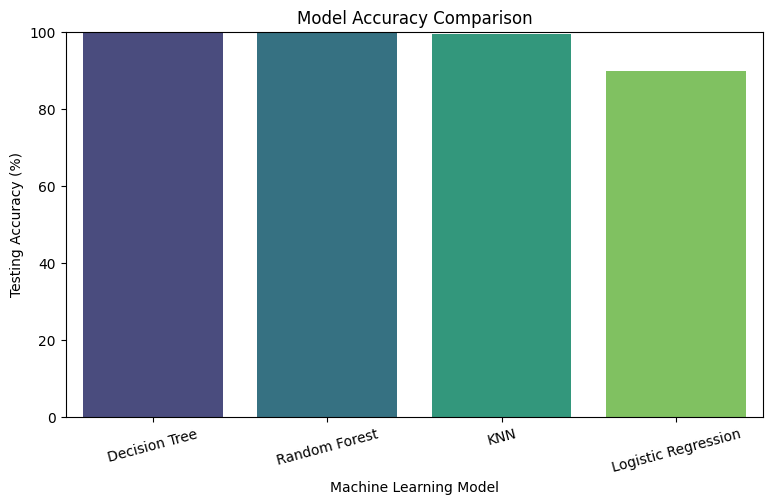

Best model: Decision Tree with testing accuracy of 99.92%


In [ ]:
comparison_df = pd.DataFrame(
    list(model_results.items()),
    columns=["Model", "Accuracy"]
)

comparison_df["Accuracy (%)"] = (comparison_df["Accuracy"] * 100).round(2)
comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

display(comparison_df[["Model", "Accuracy (%)"]])

plt.figure(figsize=(9, 5))
sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy (%)",
    palette="viridis"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Testing Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.show()

best_model_name = comparison_df.loc[0, "Model"]
best_model_accuracy = comparison_df.loc[0, "Accuracy (%)"]

print(
    f"Best model: {best_model_name} "
    f"with testing accuracy of {best_model_accuracy}%"
)

## Step 16: Confusion Matrix and Feature Importance

A confusion matrix shows which protocols the best model predicted correctly and where it made mistakes.

Feature importance shows which input features had the greatest influence on the Decision Tree’s predictions.

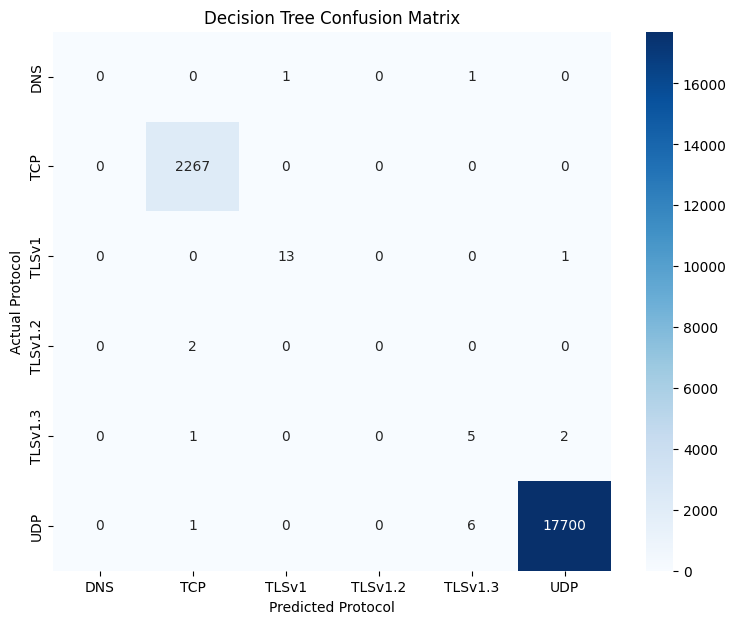

Decision Tree Feature Importance:


,Feature,Importance
0,Length,0.995730
2,Minute,0.003017
3,Second,0.001253
1,Hour,0.000000


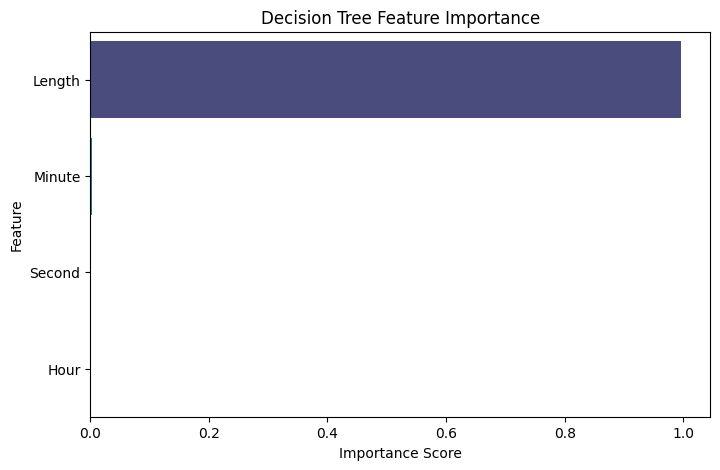

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrix for the best model: Decision Tree
cm = confusion_matrix(
    y_test,
    y_pred_tree,
    labels=model_labels
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model_target_names,
    yticklabels=model_target_names
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.show()

# Create feature-importance table and chart
feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": decision_tree_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Decision Tree Feature Importance:")
display(feature_importance_df)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=feature_importance_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()

### Feature Importance Interpretation

Packet Length was the most important feature, with an importance score of approximately 99.57%.

Minute and Second had only a very small effect, while Hour had no important effect.

This indicates that packet length was the main factor used by the Decision Tree to classify network protocols in this dataset.

## Step 17: Final Protocol Prediction

In this step, I use the best model, Decision Tree, to predict the protocol of an unseen test packet.

In [ ]:
# Select one correctly predicted unseen test packet
correct_position = np.where(y_pred_tree == y_test)[0][0]

new_packet = X_test.iloc[[correct_position]]
actual_protocol = label_encoder.inverse_transform(
    [y_test[correct_position]]
)[0]

predicted_protocol = label_encoder.inverse_transform(
    decision_tree_model.predict(new_packet)
)[0]

print("New packet features:")
display(new_packet)

print("Actual Protocol:", actual_protocol)
print("Predicted Protocol:", predicted_protocol)

if actual_protocol == predicted_protocol:
    print("\nPrediction is correct.")
else:
    print("\nPrediction is incorrect.")

New packet features:


,Length,Hour,Minute,Second
92571,40.0,11,15,16


Actual Protocol: TCP
Predicted Protocol: TCP

Prediction is correct.


## Final Conclusion

This project classified network protocols using Machine Learning.

First, the incorrectly merged dataset was repaired from 14 columns into seven correct packet columns. The data was inspected, cleaned, and prepared for machine learning.

Four models were trained and compared:

- Logistic Regression: 89.83%
- KNN: 99.54%
- Decision Tree: 99.92%
- Random Forest: 99.88%

The Decision Tree achieved the highest testing accuracy of 99.92%, so it was selected as the best model.

Packet Length was the most important feature for prediction. The final demonstration correctly predicted TCP for an unseen test packet.

One limitation is that the dataset is imbalanced because UDP packets are much more common than rare protocols. Therefore, rare protocols had lower prediction performance.

In [ ]:
import joblib

joblib.dump(decision_tree_model, "/content/best_decision_tree_model.pkl")
joblib.dump(label_encoder, "/content/protocol_label_encoder.pkl")

print("Best model and protocol encoder saved successfully.")

Best model and protocol encoder saved successfully.
